# Réseau Analogique — Classification Disque — v5 — 1 SORTIE + SEUIL

**Problème** : classifier des points à l'intérieur vs l'extérieur d'un disque centré de rayon 0.5.

**Architecture** : `[2, N_hidden..., 1]` — une seule sortie fréquentielle.  
La décision se fait par seuil sur la fréquence de sortie :
- `Fout ≥ THRESHOLD_HZ` → **Classe 1** (intérieur du disque)
- `Fout <  THRESHOLD_HZ` → **Classe 0** (extérieur du disque)

Le seuil `THRESHOLD_HZ` est optimisé automatiquement sur le train à chaque évaluation.

Accélérations :
  - `layer_forward`         : Numba JIT (`@njit`) — supprime la double boucle Python
  - `interp2d_bilinear`     : Numba JIT — interpolation compilée
  - `network_forward_mc`    : CuPy GPU — tirages Monte-Carlo en parallèle sur GPU
  - `coordinate_search`     : joblib — restarts indépendants en parallèle
  - `MIN_MARGIN_HZ = 1kHz`  : pénalité dure si |Fout - seuil| < 1 kHz

**Fix v4.1** : `Itot < rheobase` → `Fout = 0 Hz` (neurone silencieux).  
**Fix v5**   : `Itot ≥ 0` strict — pénalité dure + filtre précoce dans la recherche.

## 0. Imports & Configuration

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sys
import time
import warnings
warnings.filterwarnings('ignore')

from numba import njit, prange
import joblib
from tqdm.auto import tqdm
try:
    import cupy as cp
    GPU_AVAILABLE = True
    print('GPU détecté :', cp.cuda.runtime.getDeviceProperties(0)['name'].decode())
except Exception:
    cp = None
    GPU_AVAILABLE = False
    print('GPU non disponible — Monte-Carlo sur CPU.')

%matplotlib inline
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size']  = 11
np.set_printoptions(precision=4, suppress=True)

# ── Fichiers CSV ──────────────────────────────────────────────
INPUT_CSV   = 'input_min_conso.csv'
NEURON_CSV  = 'neuron.csv'
SYN_EXC_CSV = 'excitation20.csv'
SYN_INH_CSV = 'inhibition20.csv'

FREQ_MERGE_TOL_HZ = 1000.0

# ── Architecture  [2, N_hidden..., 1] ────────────────────────
# Dernière dimension = 1 (une seule sortie, classification par seuil)
HIDDEN_SIZES = [8,6,2]   # ex: [4] -> 2-4-1  |  [4,4] -> 2-4-4-1

# ── Recherche ────────────────────────────────────────────────
N_RESTARTS   = 8
MAX_PASSES   = 8
SEED         = 42
N_JOBS       = -1    # -1 = tous les cœurs CPU disponibles

# ── Dataset Disque ────────────────────────────────────────────
N_TRAIN     = 400
N_TEST      = 200
DISK_RADIUS = 0.5
MARGIN      = 0.05   # zone d'exclusion autour du bord

# ── Seuil de décision ─────────────────────────────────────────
# Le seuil est optimisé automatiquement sur le train à chaque évaluation.
# N_THRESHOLD_CANDIDATES = nombre de seuils candidats testés.
N_THRESHOLD_CANDIDATES = 50

# ── Score avec contrainte physique 1 kHz ─────────────────────
# La marge est maintenant |Fout - seuil| pour chaque sample.
MARGIN_SCALE       = 1e-4
IMBALANCE_PENALTY  = 0.15
MIN_MARGIN_HZ      = 1000.0
MIN_MARGIN_PENALTY = 0.5

# ── Contrainte Itot ≥ 0 (v5) ─────────────────────────────────
MIN_ITOT_A       = 0.0
MIN_ITOT_PENALTY = 1.0
ITOT_CHECK_FRAC  = 0.2

# ── Robustesse au bruit ───────────────────────────────────────
NOISE_STD_HZ = 500.0
N_MC_TRAIN   = 5
N_MC_EVAL    = 30

print('Configuration OK — architecture 1 sortie + seuil.')

GPU détecté : NVIDIA GeForce RTX 3080
Configuration OK — architecture 1 sortie + seuil.


## 1. Fonctions utilitaires

In [17]:
def read_cadence_rows(csv_path):
    df = pd.read_csv(csv_path)
    if 'Parameter' not in df.columns:
        raise ValueError(csv_path + ": colonne 'Parameter' introuvable")
    data_cols = [c for c in df.columns if c not in ['Parameter', 'Unnamed: 1']]
    def get_row(row_name, allow_non_numeric=False):
        row = df.loc[df['Parameter'] == row_name, data_cols]
        if row.empty:
            raise ValueError("Ligne '" + row_name + "' introuvable dans " + csv_path)
        values = pd.to_numeric(row.iloc[0], errors='coerce').to_numpy(dtype=float)
        if not allow_non_numeric and np.isnan(values).any():
            raise ValueError("Ligne '" + row_name + "' contient des NaN")
        return values
    return get_row

def get_clean_rows(reader, row_names):
    rows = [reader(name, allow_non_numeric=True) for name in row_names]
    mask = np.all(np.isfinite(np.vstack(rows)), axis=0)
    return [r[mask] for r in rows], mask

def strictly_monotonic_branch(x, y):
    idx = int(np.argmax(y))
    xm, ym = np.asarray(x[:idx+1], float), np.asarray(y[:idx+1], float)
    o = np.argsort(xm)
    return xm[o], ym[o]

def merge_close_values(values, tol):
    vals = np.sort(np.asarray(values, float))
    groups = [[vals[0]]]
    for v in vals[1:]:
        if abs(v - np.mean(groups[-1])) <= tol:
            groups[-1].append(v)
        else:
            groups.append([v])
    return np.array([np.mean(g) for g in groups])

def snap_to_axis(values, axis):
    return np.array([axis[np.argmin(np.abs(axis - v))]
                     for v in np.asarray(values, float)])

def build_grid_tolerant(W_all, F_all, Y_all, freq_tol=1000.0):
    W_all, F_all, Y_all = (np.asarray(a, float) for a in (W_all, F_all, Y_all))
    W_unique = np.unique(W_all)
    F_axis   = merge_close_values(np.unique(F_all), tol=freq_tol)
    F_snap   = snap_to_axis(F_all, F_axis)
    z_grid   = np.empty((len(W_unique), len(F_axis)))
    for i, w in enumerate(W_unique):
        for j, f in enumerate(F_axis):
            mask = np.isclose(W_all, w) & np.isclose(F_snap, f)
            if not mask.any():
                raise ValueError('Point manquant W=' + str(w) + ' F=' + str(f))
            z_grid[i, j] = np.mean(Y_all[mask])
    return W_unique, F_axis, z_grid

print('Fonctions utilitaires OK.')

Fonctions utilitaires OK.


## 2. Chargement des modèles Cadence

In [18]:
inp = read_cadence_rows(INPUT_CSV)
VEX_IN, FSPIKES_IN = inp('Vex'), inp('Fspikes')
INPUT_V_AXIS, INPUT_F_AXIS = strictly_monotonic_branch(VEX_IN, FSPIKES_IN)

neuro = read_cadence_rows(NEURON_CSV)
IEX_NEURO, FSPIKES_NEURO = neuro('Iex'), neuro('Fspikes')
NEURON_I_AXIS, NEURON_F_AXIS = strictly_monotonic_branch(IEX_NEURO, FSPIKES_NEURO)

syn_exc = read_cadence_rows(SYN_EXC_CSV)
(W2_EXC, FPRE_EXC, IPOST_EXC), _ = get_clean_rows(syn_exc, ['W2', 'Fpre', 'Ipost'])
W_EXC_AXIS, F_EXC_AXIS, IPOST_EXC_GRID = build_grid_tolerant(
    W2_EXC, FPRE_EXC, IPOST_EXC, FREQ_MERGE_TOL_HZ)

syn_inh = read_cadence_rows(SYN_INH_CSV)
(W2_INH, FPRE_INH, IPOST_INH), _ = get_clean_rows(syn_inh, ['W2', 'Fpre', 'Ipost'])
W_INH_AXIS, F_INH_AXIS, IPOST_INH_GRID = build_grid_tolerant(
    W2_INH, FPRE_INH, IPOST_INH, FREQ_MERGE_TOL_HZ)

V_MIN       = float(INPUT_V_AXIS[0])
V_MAX       = float(INPUT_V_AXIS[-1])

# ── Architecture 1 sortie ─────────────────────────────────────
LAYER_SIZES = [2] + HIDDEN_SIZES + [1]

NEURON_I_RHEOBASE = float(NEURON_I_AXIS[0])

_INPUT_V_AXIS   = np.ascontiguousarray(INPUT_V_AXIS,   dtype=np.float64)
_INPUT_F_AXIS   = np.ascontiguousarray(INPUT_F_AXIS,   dtype=np.float64)
_NEURON_I_AXIS  = np.ascontiguousarray(NEURON_I_AXIS,  dtype=np.float64)
_NEURON_F_AXIS  = np.ascontiguousarray(NEURON_F_AXIS,  dtype=np.float64)
_W_EXC_AXIS     = np.ascontiguousarray(W_EXC_AXIS,     dtype=np.float64)
_F_EXC_AXIS     = np.ascontiguousarray(F_EXC_AXIS,     dtype=np.float64)
_IPOST_EXC_GRID = np.ascontiguousarray(IPOST_EXC_GRID, dtype=np.float64)
_W_INH_AXIS     = np.ascontiguousarray(W_INH_AXIS,     dtype=np.float64)
_F_INH_AXIS     = np.ascontiguousarray(F_INH_AXIS,     dtype=np.float64)
_IPOST_INH_GRID = np.ascontiguousarray(IPOST_INH_GRID, dtype=np.float64)
_F_MAX          = float(NEURON_F_AXIS[-1])

print('Input  V : ' + str(round(V_MIN*1e3,1)) + ' mV -> ' + str(round(V_MAX*1e3,1)) + ' mV')
print('Neuron I : ' + str(round(NEURON_I_AXIS[0]*1e12,1))
      + ' pA -> ' + str(round(NEURON_I_AXIS[-1]*1e12,1)) + ' pA')
print('Neuron rheobase : ' + str(round(NEURON_I_RHEOBASE*1e12,2)) + ' pA')
print('Exc W (um) : ' + str(W_EXC_AXIS))
print('Inh W (um) : ' + str(W_INH_AXIS))
print('Architecture : ' + str(LAYER_SIZES) + '  ← 1 sortie scalaire')

Input  V : -100.0 mV -> 100.0 mV
Neuron I : 3.0 pA -> 1000.0 pA
Neuron rheobase : 3.0 pA
Exc W (um) : [0.135  0.2858 0.4366 0.5874 0.7382 0.8889 1.04   1.191  1.341  1.492
 1.643  1.794  1.944  2.095  2.246  2.397  2.548  2.698  2.849  3.    ]
Inh W (um) : [0.135  0.1805 0.2261 0.2716 0.3171 0.3626 0.4082 0.4537 0.4992 0.5447
 0.5903 0.6358 0.6813 0.7268 0.7724 0.8179 0.8634 0.9089 0.9545 1.    ]
Architecture : [2, 8, 6, 2, 1]  ← 1 sortie scalaire


## 3. Noyaux Numba JIT

In [19]:
@njit(cache=True)
def _interp1d_numba(x, xp, fp):
    """
    Interpolation 1D compilée Numba.
    Retourne 0.0 si x <= xp[0] → neurone silencieux sous la rheobase.
    """
    if x <= xp[0]:
        return 0.0
    if x >= xp[-1]:
        return fp[-1]
    lo, hi = 0, len(xp) - 1
    while hi - lo > 1:
        mid = (lo + hi) // 2
        if xp[mid] <= x:
            lo = mid
        else:
            hi = mid
    t = (x - xp[lo]) / (xp[hi] - xp[lo])
    return fp[lo] + t * (fp[hi] - fp[lo])


@njit(cache=True)
def _interp2d_numba(x, y, x_axis, y_axis, z_grid):
    """Interpolation bilinéaire compilée Numba."""
    x = max(x_axis[0], min(x_axis[-1], x))
    y = max(y_axis[0], min(y_axis[-1], y))
    lx = 0
    for k in range(len(x_axis) - 1):
        if x_axis[k] <= x < x_axis[k+1]:
            lx = k
            break
    else:
        lx = len(x_axis) - 2
    ly = 0
    for k in range(len(y_axis) - 1):
        if y_axis[k] <= y < y_axis[k+1]:
            ly = k
            break
    else:
        ly = len(y_axis) - 2
    x1, x2 = x_axis[lx], x_axis[lx+1]
    y1, y2 = y_axis[ly], y_axis[ly+1]
    tx = 0.0 if x2 == x1 else (x - x1) / (x2 - x1)
    ty = 0.0 if y2 == y1 else (y - y1) / (y2 - y1)
    return (z_grid[lx,   ly  ] * (1-tx) * (1-ty) +
            z_grid[lx+1, ly  ] * tx     * (1-ty) +
            z_grid[lx,   ly+1] * (1-tx) * ty     +
            z_grid[lx+1, ly+1] * tx     * ty)


@njit(cache=True, parallel=True)
def _layer_forward_numba(Fin, signs_flat, widths_flat, N, M,
                          w_exc, f_exc, g_exc,
                          w_inh, f_inh, g_inh,
                          ni_axis, nf_axis):
    """Layer forward compilé Numba, parallélisme sur les synapses."""
    Iconn = np.zeros(N * M)
    for k in prange(N * M):
        i = k // M
        j = k  % M
        s = signs_flat[k]
        w = widths_flat[k]
        f = Fin[i]
        if s == 1:
            Iconn[k] = _interp2d_numba(w, f, w_exc, f_exc, g_exc)
        elif s == -1:
            Iconn[k] = -_interp2d_numba(w, f, w_inh, f_inh, g_inh)
    Itot = np.zeros(M)
    for k in range(N * M):
        Itot[k % M] += Iconn[k]
    Fout = np.empty(M)
    for j in range(M):
        Fout[j] = _interp1d_numba(Itot[j], ni_axis, nf_axis)
    return Fout, Iconn.reshape((N, M)), Itot


def layer_forward(Fin_vec_Hz, sign_matrix, width_matrix_um):
    """Wrapper Python de _layer_forward_numba."""
    N, M = sign_matrix.shape
    Fout, Iconn, Itot = _layer_forward_numba(
        np.ascontiguousarray(Fin_vec_Hz, np.float64),
        sign_matrix.ravel().astype(np.float64),
        width_matrix_um.ravel().astype(np.float64),
        N, M,
        _W_EXC_AXIS, _F_EXC_AXIS, _IPOST_EXC_GRID,
        _W_INH_AXIS, _F_INH_AXIS, _IPOST_INH_GRID,
        _NEURON_I_AXIS, _NEURON_F_AXIS
    )
    return Fout, Iconn, Itot


def input_f_of_v(Vin_V):
    return float(_interp1d_numba(float(Vin_V), _INPUT_V_AXIS, _INPUT_F_AXIS))

def neuron_f_of_i(Iin_A):
    if Iin_A < NEURON_I_RHEOBASE:
        return 0.0
    return float(_interp1d_numba(float(Iin_A), _NEURON_I_AXIS, _NEURON_F_AXIS))


# ── Warm-up Numba ──────────────────────────────────────────────
print('Compilation Numba JIT...')
t0 = time.time()
_dummy_signs  = np.array([[1.0], [-1.0]])
_dummy_widths = np.array([[float(W_EXC_AXIS[0])], [float(W_INH_AXIS[0])]])
_dummy_F      = np.array([1000.0, 2000.0])
layer_forward(_dummy_F, _dummy_signs, _dummy_widths)
print(f'  JIT compilé en {time.time()-t0:.1f}s')

print(f'  neuron_f_of_i(-1e-9) = {neuron_f_of_i(-1e-9):.1f} Hz  (attendu: 0.0)')
print(f'  neuron_f_of_i(0.0)   = {neuron_f_of_i(0.0):.1f} Hz  (attendu: 0.0)')
print(f'  neuron_f_of_i(rheo)  = {neuron_f_of_i(NEURON_I_RHEOBASE):.1f} Hz  (attendu: ~{NEURON_F_AXIS[0]:.0f})')
print('Noyaux Numba OK.')

Compilation Numba JIT...
  JIT compilé en 0.0s
  neuron_f_of_i(-1e-9) = 0.0 Hz  (attendu: 0.0)
  neuron_f_of_i(0.0)   = 0.0 Hz  (attendu: 0.0)
  neuron_f_of_i(rheo)  = 0.0 Hz  (attendu: ~3083)
Noyaux Numba OK.


## 4. Propagation CPU + GPU

In [20]:
def network_forward_single(Vin_vec_V, signs, widths):
    """Forward déterministe, un seul sample. Retourne un scalaire (1 sortie)."""
    F = np.array([input_f_of_v(v) for v in Vin_vec_V])
    for sm, wm in zip(signs, widths):
        F, _, _ = layer_forward(F, sm, wm)
    return float(F[0])   # scalaire — unique neurone de sortie


def network_forward_dataset(V_dataset, signs, widths):
    """Forward déterministe sur tout le dataset. Retourne un vecteur 1D."""
    return np.array([network_forward_single(Vin, signs, widths)
                     for Vin in V_dataset])  # shape (N,)


def network_forward_with_itot(V_dataset, signs, widths):
    """
    Forward déterministe + collecte de tous les Itot intermédiaires.
    Retourne (Fout_1d, all_itot_array).
    """
    all_itot = []
    Fouts = []
    for Vin in V_dataset:
        F = np.array([input_f_of_v(v) for v in Vin])
        for sm, wm in zip(signs, widths):
            F, _, Itot = layer_forward(F, sm, wm)
            all_itot.extend(Itot.tolist())
        Fouts.append(float(F[0]))
    return np.array(Fouts), np.array(all_itot)


if GPU_AVAILABLE:
    def network_forward_mc(V_dataset, signs, widths, noise_std, n_mc):
        """Monte-Carlo sur GPU (CuPy). Retourne la fréquence moyenne (1D)."""
        Fout_cpu = network_forward_dataset(V_dataset, signs, widths)  # (N,)
        Fout_gpu = cp.asarray(Fout_cpu)
        noise    = cp.random.normal(0.0, noise_std, (n_mc, len(V_dataset)))
        Fout_mc  = cp.clip(Fout_gpu[None, :] + noise, 0.0, _F_MAX)
        return cp.asnumpy(Fout_mc.mean(axis=0))  # (N,)
else:
    def network_forward_mc(V_dataset, signs, widths, noise_std, n_mc):
        """Monte-Carlo CPU fallback."""
        rng = np.random.default_rng()
        acc = np.zeros(len(V_dataset))
        for _ in range(n_mc):
            Fout = network_forward_dataset(V_dataset, signs, widths)
            acc += np.clip(Fout + rng.normal(0, noise_std, Fout.shape), 0, _F_MAX)
        return acc / n_mc


print('Propagation OK.')

Propagation OK.


## 5. Dataset Disque

Train : 400 pts  cl1(int)=68  cl0(ext)=332
Test  : 200 pts  cl1(int)=40  cl0(ext)=160


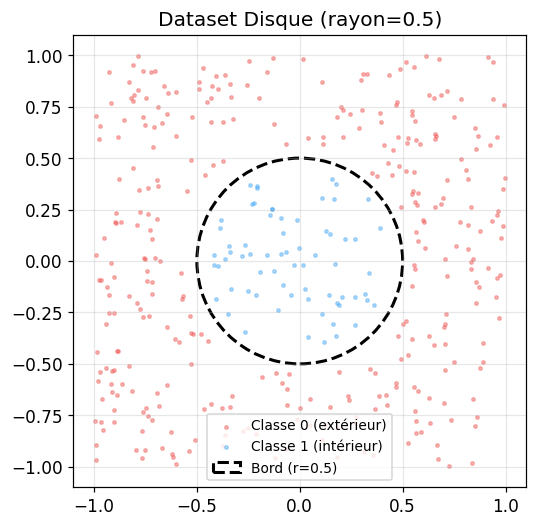

In [21]:
def label_disk(X, radius=DISK_RADIUS):
    """Classe 1 = intérieur (r < radius), Classe 0 = extérieur."""
    return (X[:, 0]**2 + X[:, 1]**2 < radius**2).astype(int)

def make_dataset(n, seed=0):
    rng = np.random.default_rng(seed)
    pts = []
    while sum(len(p) for p in pts) < n:
        batch = rng.uniform(-1.0, 1.0, size=(n * 2, 2))
        r    = np.sqrt(batch[:, 0]**2 + batch[:, 1]**2)
        mask = np.abs(r - DISK_RADIUS) > MARGIN
        pts.append(batch[mask])
    data = np.vstack(pts)[:n]
    return data, label_disk(data)

def xy_to_voltage(X):
    return V_MIN + (np.asarray(X, float) + 1.0) * (V_MAX - V_MIN) / 2.0

X_train, y_train = make_dataset(N_TRAIN, seed=SEED)
X_test,  y_test  = make_dataset(N_TEST,  seed=SEED + 1)
V_train = xy_to_voltage(X_train)
V_test  = xy_to_voltage(X_test)

print('Train : ' + str(len(y_train)) + ' pts  cl1(int)=' + str(y_train.sum())
      + '  cl0(ext)=' + str((1-y_train).sum()))
print('Test  : ' + str(len(y_test))  + ' pts  cl1(int)=' + str(y_test.sum())
      + '  cl0(ext)=' + str((1-y_test).sum()))

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(X_train[y_train==0, 0], X_train[y_train==0, 1],
           s=5, alpha=0.4, c='#EF5350', label='Classe 0 (extérieur)')
ax.scatter(X_train[y_train==1, 0], X_train[y_train==1, 1],
           s=5, alpha=0.4, c='#42A5F5', label='Classe 1 (intérieur)')
circle = plt.Circle((0, 0), DISK_RADIUS, color='k', fill=False,
                    lw=2, ls='--', label=f'Bord (r={DISK_RADIUS})')
ax.add_patch(circle)
ax.set_title(f'Dataset Disque (rayon={DISK_RADIUS})')
ax.set_aspect('equal')
ax.set_xlim(-1.1, 1.1); ax.set_ylim(-1.1, 1.1)
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

## 6. Seuil optimal + Évaluation

Avec une seule sortie fréquentielle, la décision est :
- `Fout ≥ threshold` → **Classe 1** (intérieur)
- `Fout <  threshold` → **Classe 0** (extérieur)

`find_best_threshold` balaye `N_THRESHOLD_CANDIDATES` valeurs uniformément réparties  
entre `min(Fout)` et `max(Fout)` et retient celle qui maximise la balanced accuracy.

La **marge** est maintenant `|Fout - threshold|` pour chaque sample :  
c'est la distance fréquentielle au seuil de décision, analogue à la marge de classe  
dans la version 2 sorties.

In [22]:
def find_best_threshold(Fout_1d, y_true, n_candidates=N_THRESHOLD_CANDIDATES):
    """
    Balaye n_candidates seuils et retourne celui qui maximise la balanced accuracy.
    Fout_1d : vecteur 1D de fréquences de sortie.
    y_true  : labels 0/1.
    Retourne (best_threshold, best_bal_acc).
    """
    f_min, f_max = float(Fout_1d.min()), float(Fout_1d.max())
    if f_max <= f_min:
        # Toutes les sorties identiques — seuil au milieu, acc = 0.5
        return (f_min + f_max) / 2.0, 0.5

    candidates = np.linspace(f_min, f_max, n_candidates + 2)[1:-1]  # évite les bords
    y = np.asarray(y_true, int)
    mask0, mask1 = (y == 0), (y == 1)

    best_thr, best_acc = candidates[0], -1.0
    for thr in candidates:
        preds = (Fout_1d >= thr).astype(int)
        acc0  = float(np.mean(preds[mask0] == 0)) if mask0.any() else 0.0
        acc1  = float(np.mean(preds[mask1] == 1)) if mask1.any() else 0.0
        bal   = 0.5 * (acc0 + acc1)
        if bal > best_acc:
            best_acc, best_thr = bal, thr
    return best_thr, best_acc


def evaluate_network(V_dataset, y_true, signs, widths,
                     threshold=None, noise_std=0.0, n_mc=1):
    """
    Évalue le réseau à 1 sortie.

    threshold=None  → seuil optimisé automatiquement sur ce dataset.
    threshold=float → seuil fixé (utile pour évaluer le test avec le seuil du train).

    Score = bal_acc
            + MARGIN_SCALE    * bal_margin_vs_threshold
            - IMBALANCE_PENALTY * |acc0-acc1|
            - MIN_MARGIN_PENALTY * frac_below_1kHz
            - MIN_ITOT_PENALTY  * frac_itot_neg
    """
    # Forward + Itot
    Fout, all_itot = network_forward_with_itot(V_dataset, signs, widths)

    # Monte-Carlo sur les sorties si demandé
    if noise_std > 0 and n_mc > 1:
        Fout = network_forward_mc(V_dataset, signs, widths, noise_std, n_mc)

    y = np.asarray(y_true, int)
    mask0, mask1 = (y == 0), (y == 1)

    # Seuil : optimisé ou imposé
    if threshold is None:
        thr, _ = find_best_threshold(Fout, y)
    else:
        thr = float(threshold)

    preds = (Fout >= thr).astype(int)
    acc0  = float(np.mean(preds[mask0] == 0)) if mask0.any() else 0.0
    acc1  = float(np.mean(preds[mask1] == 1)) if mask1.any() else 0.0
    bal_acc = 0.5 * (acc0 + acc1)

    # Marge = distance de chaque sortie au seuil, signée selon la classe
    # Classe 1 : on veut Fout >> thr → marge = Fout - thr  (positive si correct)
    # Classe 0 : on veut Fout << thr → marge = thr - Fout  (positive si correct)
    margins = np.where(y == 1, Fout - thr, thr - Fout)
    margin0    = float(np.mean(margins[mask0])) if mask0.any() else 0.0
    margin1    = float(np.mean(margins[mask1])) if mask1.any() else 0.0
    bal_margin = 0.5 * (margin0 + margin1)

    frac_below_margin = float(np.mean(margins < MIN_MARGIN_HZ))

    # Contrainte Itot ≥ 0 (v5)
    frac_itot_neg = float(np.mean(all_itot < MIN_ITOT_A))

    score = (bal_acc
             + MARGIN_SCALE       * bal_margin
             - IMBALANCE_PENALTY  * abs(acc0 - acc1)
             - MIN_MARGIN_PENALTY * frac_below_margin
             - MIN_ITOT_PENALTY   * frac_itot_neg)

    return {'preds': preds, 'Fout': Fout,
            'threshold': thr,
            'acc0': acc0, 'acc1': acc1, 'bal_acc': bal_acc,
            'bal_margin': bal_margin,
            'frac_below': frac_below_margin,
            'frac_itot_neg': frac_itot_neg,
            'score': score}


def print_results(label, m):
    print('\n=== ' + label + ' ===')
    print(f'  seuil décision  = {m["threshold"]*1e-3:.3f} kHz')
    print('  acc cl0 (ext)   = ' + str(round(m['acc0'], 4)))
    print('  acc cl1 (int)   = ' + str(round(m['acc1'], 4)))
    print('  bal_acc         = ' + str(round(m['bal_acc'], 4)))
    print('  marge moy.      = ' + str(round(m['bal_margin'] * 1e-3, 3)) + ' kHz')
    print('  pts < 1 kHz     = ' + str(round(m['frac_below'] * 100, 1)) + ' %')
    print('  Itot < 0        = ' + str(round(m['frac_itot_neg'] * 100, 2)) + ' %')
    print('  score           = ' + str(round(m['score'], 6)))


ALL_CANDIDATES = [
    [(+1, float(w)) for w in W_EXC_AXIS] + [(-1, float(w)) for w in W_INH_AXIS]
    for _ in range(len(LAYER_SIZES) - 1)
]
print('Candidats par connexion : ' + str(len(ALL_CANDIDATES[0]))
      + ' (' + str(len(W_EXC_AXIS)) + ' EXC + ' + str(len(W_INH_AXIS)) + ' INH)')


def random_network(rng):
    signs, widths = [], []
    for li, (n_in, n_out) in enumerate(zip(LAYER_SIZES[:-1], LAYER_SIZES[1:])):
        exc_w = [c[1] for c in ALL_CANDIDATES[li] if c[0] == +1]
        inh_w = [c[1] for c in ALL_CANDIDATES[li] if c[0] == -1]
        s = rng.choice([-1, 1], size=(n_in, n_out))
        w = np.zeros((n_in, n_out))
        for i in range(n_in):
            for j in range(n_out):
                w[i, j] = rng.choice(exc_w if s[i, j] == 1 else inh_w)
        signs.append(s)
        widths.append(w)
    return signs, widths

print('evaluate_network OK — mode 1 sortie + seuil optimal.')

Candidats par connexion : 40 (20 EXC + 20 INH)
evaluate_network OK — mode 1 sortie + seuil optimal.


## 7. Coordinate search

Le seuil est optimisé sur le train **à chaque évaluation** pendant la recherche,  
donc la recherche cherche simultanément les bons poids ET le bon seuil.

In [23]:
# Sous-ensemble fixe pour le filtre précoce Itot ≥ 0
_N_ITOT_CHECK = max(10, int(len(V_train) * ITOT_CHECK_FRAC))
_V_ITOT_CHECK = V_train[:_N_ITOT_CHECK]
print(f'Filtre Itot précoce : {_N_ITOT_CHECK} samples ({ITOT_CHECK_FRAC*100:.0f}% du train)')


def _itot_is_valid(signs, widths):
    """
    Vérifie rapidement (sous-ensemble 20%) qu'aucun Itot n'est < 0.
    Retourne True si physiquement valide.
    """
    _, all_itot = network_forward_with_itot(_V_ITOT_CHECK, signs, widths)
    return bool(np.all(all_itot >= MIN_ITOT_A))


def _one_restart(restart_idx, rng_seed, pbar_restarts=None):
    """Un restart complet de coordinate search — 1 sortie + seuil (v5)."""
    rng = np.random.default_rng(rng_seed)
    all_conns = [
        (l, i, j)
        for l, (n_in, n_out) in enumerate(zip(LAYER_SIZES[:-1], LAYER_SIZES[1:]))
        for i in range(n_in)
        for j in range(n_out)
    ]

    signs, widths = random_network(rng)
    tr = evaluate_network(V_train, y_train, signs, widths,
                          noise_std=NOISE_STD_HZ, n_mc=N_MC_TRAIN)
    # On fixe le seuil du train pour évaluer le test de façon cohérente
    va = evaluate_network(V_test, y_test, signs, widths,
                          threshold=tr['threshold'])

    history = [{'pass': 0,
                'tr_bal_acc': tr['bal_acc'], 'tr_score': tr['score'],
                'va_bal_acc': va['bal_acc'], 'va_score': va['score'],
                'threshold_khz': tr['threshold'] * 1e-3,
                'va_itot_neg_pct': va['frac_itot_neg'] * 100}]
    t0 = time.time()

    R = f'R{restart_idx+1:02d}'
    print(f'  {R} démarré | tr_acc={tr["bal_acc"]:.3f} | va_acc={va["bal_acc"]:.3f} '
          f'| thr={tr["threshold"]*1e-3:.1f}kHz | Itot<0={tr["frac_itot_neg"]*100:.1f}%')

    for pass_idx in range(MAX_PASSES):
        improved   = False
        conn_order = list(all_conns)
        rng.shuffle(conn_order)
        t_pass = time.time()
        n_filtered = 0

        for l, i, j in conn_order:
            orig_s = signs[l][i, j]
            orig_w = widths[l][i, j]
            best_s, best_w, best_c = orig_s, orig_w, tr['score']

            for cs, cw in ALL_CANDIDATES[l]:
                if cs == orig_s and np.isclose(cw, orig_w):
                    continue

                signs[l][i, j]  = cs
                widths[l][i, j] = cw

                # Filtre précoce Itot ≥ 0
                if not _itot_is_valid(signs, widths):
                    n_filtered += 1
                    signs[l][i, j]  = orig_s
                    widths[l][i, j] = orig_w
                    continue

                ctr = evaluate_network(V_train, y_train, signs, widths,
                                       noise_std=NOISE_STD_HZ, n_mc=N_MC_TRAIN)
                if ctr['score'] > best_c:
                    best_c, best_s, best_w = ctr['score'], cs, cw

                signs[l][i, j]  = orig_s
                widths[l][i, j] = orig_w

            signs[l][i, j]  = best_s
            widths[l][i, j] = best_w
            if best_c > tr['score']:
                tr = evaluate_network(V_train, y_train, signs, widths,
                                      noise_std=NOISE_STD_HZ, n_mc=N_MC_TRAIN)
                improved = True

        # Évaluation test avec le seuil trouvé sur le train
        va = evaluate_network(V_test, y_test, signs, widths,
                              threshold=tr['threshold'])
        history.append({'pass': pass_idx + 1,
                        'tr_bal_acc': tr['bal_acc'], 'tr_score': tr['score'],
                        'va_bal_acc': va['bal_acc'], 'va_score': va['score'],
                        'threshold_khz': tr['threshold'] * 1e-3,
                        'va_itot_neg_pct': va['frac_itot_neg'] * 100})

        elapsed_pass = time.time() - t_pass
        status = 'converge' if not improved else ''
        print(f'  {R} pass {pass_idx+1}/{MAX_PASSES} | '
              f'tr={tr["bal_acc"]:.3f} va={va["bal_acc"]:.3f} | '
              f'thr={tr["threshold"]*1e-3:.1f}kHz | '
              f'marge={va["bal_margin"]*1e-3:.1f}kHz | '
              f'Itot<0={va["frac_itot_neg"]*100:.1f}% | '
              f'filtrés={n_filtered} | '
              f'{elapsed_pass:.0f}s {status}')

        if not improved:
            break

    elapsed = time.time() - t0
    print(f'  ✓ {R} FINI | va_acc={va["bal_acc"]:.4f} | '
          f'thr={tr["threshold"]*1e-3:.1f}kHz | '
          f'Itot<0={va["frac_itot_neg"]*100:.2f}% | {elapsed:.0f}s')

    if pbar_restarts is not None:
        pbar_restarts.update(1)

    return {
        'signs':     [s.copy() for s in signs],
        'widths':    [w.copy() for w in widths],
        'threshold': tr['threshold'],   # seuil optimal trouvé sur le train
        'va_score':  va['score'],
        'tr_score':  tr['score'],
        'history':   history,
    }


def coordinate_search():
    """Lance N_RESTARTS restarts en parallèle via joblib."""
    seeds = [SEED + r * 1000 for r in range(N_RESTARTS)]

    pbar_restarts = tqdm(
        total=N_RESTARTS, leave=True,
        desc='Restarts terminés',
        bar_format='{l_bar}{bar}| {n}/{total} [{elapsed}]'
    )

    results = joblib.Parallel(n_jobs=N_JOBS, prefer='threads')(
        joblib.delayed(_one_restart)(r, seeds[r], pbar_restarts)
        for r in range(N_RESTARTS)
    )

    pbar_restarts.close()

    best = max(results, key=lambda r: (r['va_score'], r['tr_score']))
    print(f'\n★ Meilleur restart : va_score={best["va_score"]:.5f} | '
          f'seuil={best["threshold"]*1e-3:.2f} kHz')
    return best['signs'], best['widths'], best['threshold'], best['history']

Filtre Itot précoce : 80 samples (20% du train)


## 8. Entraînement

In [ ]:
n_conn = sum(LAYER_SIZES[i] * LAYER_SIZES[i+1] for i in range(len(LAYER_SIZES) - 1))
print('Architecture    : ' + str(LAYER_SIZES) + '  ← 1 sortie')
print('Problème        : Disque centré (r=' + str(DISK_RADIUS) + ')')
print('Restarts        : ' + str(N_RESTARTS) + '  (parallèles)')
print('Max passes      : ' + str(MAX_PASSES))
print('Connexions      : ' + str(n_conn))
print('Candidats/conn  : ' + str(len(ALL_CANDIDATES[0])))
print('Seuil candidats : ' + str(N_THRESHOLD_CANDIDATES) + ' (optimisé auto)')
print('NOISE_STD_HZ    : ' + str(NOISE_STD_HZ) + ' Hz')
print('MIN_MARGIN_HZ   : ' + str(MIN_MARGIN_HZ) + ' Hz')
print('MIN_ITOT_A      : ' + str(MIN_ITOT_A) + ' A')
print('GPU MC          : ' + str(GPU_AVAILABLE))

signs, widths, best_threshold, history = coordinate_search()
print(f'\nSeuil de décision retenu : {best_threshold*1e-3:.3f} kHz')

Architecture    : [2, 8, 6, 2, 1]  ← 1 sortie
Problème        : Disque centré (r=0.5)
Restarts        : 8  (parallèles)
Max passes      : 8
Connexions      : 78
Candidats/conn  : 40
Seuil candidats : 50 (optimisé auto)
NOISE_STD_HZ    : 500.0 Hz
MIN_MARGIN_HZ   : 1000.0 Hz
MIN_ITOT_A      : 0.0 A
GPU MC          : True


Restarts terminés:   0%|          | 0/8 [00:00]

  R05 démarré | tr_acc=0.544 | va_acc=0.500 | thr=185.6kHz | Itot<0=11.8%
  R01 démarré | tr_acc=0.549 | va_acc=0.500 | thr=162.1kHz | Itot<0=2.2%
  R04 démarré | tr_acc=0.540 | va_acc=0.500 | thr=0.1kHz | Itot<0=5.9%
  R02 démarré | tr_acc=0.540 | va_acc=0.500 | thr=146.3kHz | Itot<0=18.9%
  R07 démarré | tr_acc=0.537 | va_acc=0.500 | thr=0.1kHz | Itot<0=17.1%
  R08 démarré | tr_acc=0.505 | va_acc=0.500 | thr=192.7kHz | Itot<0=5.9%
  R03 démarré | tr_acc=0.566 | va_acc=0.500 | thr=169.7kHz | Itot<0=0.1%
  R06 démarré | tr_acc=0.567 | va_acc=0.500 | thr=0.1kHz | Itot<0=17.4%


Restarts terminés:  12%|█▎        | 1/8 [05:25]

  R07 pass 1/8 | tr=0.537 va=0.500 | thr=0.1kHz | marge=0.0kHz | Itot<0=17.3% | filtrés=3042 | 324s converge
  ✓ R07 FINI | va_acc=0.5000 | thr=0.1kHz | Itot<0=17.26% | 324s


Restarts terminés:  25%|██▌       | 2/8 [05:25]

  R02 pass 1/8 | tr=0.540 va=0.500 | thr=146.3kHz | marge=0.0kHz | Itot<0=19.0% | filtrés=3042 | 324s converge
  ✓ R02 FINI | va_acc=0.5000 | thr=146.3kHz | Itot<0=19.03% | 324s


Restarts terminés:  38%|███▊      | 3/8 [05:26]

  R06 pass 1/8 | tr=0.567 va=0.500 | thr=0.1kHz | marge=0.0kHz | Itot<0=17.5% | filtrés=3042 | 325s converge
  ✓ R06 FINI | va_acc=0.5000 | thr=0.1kHz | Itot<0=17.53% | 325s
  R05 pass 1/8 | tr=0.544 va=0.500 | thr=185.6kHz | marge=-0.0kHz | Itot<0=11.8% | filtrés=3042 | 325s converge
  ✓ R05 FINI | va_acc=0.5000 | thr=185.6kHz | Itot<0=11.76% | 325s
  R04 pass 1/8 | tr=0.539 va=0.500 | thr=192.9kHz | marge=0.0kHz | Itot<0=0.0% | filtrés=1540 | 1095s 
  R01 pass 1/8 | tr=0.526 va=0.500 | thr=162.0kHz | marge=-0.0kHz | Itot<0=0.0% | filtrés=1443 | 1143s 
  R03 pass 1/8 | tr=0.516 va=0.500 | thr=164.6kHz | marge=0.0kHz | Itot<0=0.0% | filtrés=1385 | 1174s 
  R08 pass 1/8 | tr=0.515 va=0.500 | thr=192.7kHz | marge=0.0kHz | Itot<0=0.0% | filtrés=1155 | 1292s 
  R04 pass 2/8 | tr=0.613 va=0.500 | thr=193.0kHz | marge=0.0kHz | Itot<0=0.0% | filtrés=69 | 1674s 
  R01 pass 2/8 | tr=0.555 va=0.500 | thr=177.5kHz | marge=0.0kHz | Itot<0=0.0% | filtrés=142 | 1642s 
  R03 pass 2/8 | tr=0.587 va=0.

In [ ]:
n_conn = sum(LAYER_SIZES[i] * LAYER_SIZES[i+1] for i in range(len(LAYER_SIZES) - 1))
print('Architecture    : ' + str(LAYER_SIZES) + '  ← 1 sortie')
print('Problème        : Disque centré (r=' + str(DISK_RADIUS) + ')')
print('Restarts        : ' + str(N_RESTARTS) + '  (parallèles)')
print('Max passes      : ' + str(MAX_PASSES))
print('Connexions      : ' + str(n_conn))
print('Candidats/conn  : ' + str(len(ALL_CANDIDATES[0])))
print('Seuil candidats : ' + str(N_THRESHOLD_CANDIDATES) + ' (optimisé auto)')
print('NOISE_STD_HZ    : ' + str(NOISE_STD_HZ) + ' Hz')
print('MIN_MARGIN_HZ   : ' + str(MIN_MARGIN_HZ) + ' Hz')
print('MIN_ITOT_A      : ' + str(MIN_ITOT_A) + ' A')
print('GPU MC          : ' + str(GPU_AVAILABLE))

signs, widths, best_threshold, history = coordinate_search()
print(f'\nSeuil de décision retenu : {best_threshold*1e-3:.3f} kHz')

Architecture    : [2, 2, 2, 2, 2, 1]  ← 1 sortie
Problème        : Disque centré (r=0.5)
Restarts        : 8  (parallèles)
Max passes      : 8
Connexions      : 18
Candidats/conn  : 40
Seuil candidats : 50 (optimisé auto)
NOISE_STD_HZ    : 500.0 Hz
MIN_MARGIN_HZ   : 1000.0 Hz
MIN_ITOT_A      : 0.0 A
GPU MC          : True


Restarts terminés:   0%|          | 0/8 [00:00]

  R01 démarré | tr_acc=0.522 | va_acc=0.500 | thr=85.1kHz | Itot<0=11.1%
  R08 démarré | tr_acc=0.522 | va_acc=0.500 | thr=0.4kHz | Itot<0=22.2%
  R05 démarré | tr_acc=0.544 | va_acc=0.494 | thr=157.4kHz | Itot<0=11.1%
  R07 démarré | tr_acc=0.528 | va_acc=0.500 | thr=0.0kHz | Itot<0=22.2%
  R02 démarré | tr_acc=0.503 | va_acc=0.500 | thr=188.3kHz | Itot<0=15.2%
  R04 démarré | tr_acc=0.517 | va_acc=0.500 | thr=0.2kHz | Itot<0=33.3%
  R03 démarré | tr_acc=0.527 | va_acc=0.500 | thr=0.3kHz | Itot<0=33.3%
  R06 démarré | tr_acc=0.518 | va_acc=0.500 | thr=0.5kHz | Itot<0=31.2%


Restarts terminés:  50%|█████     | 4/8 [01:27]

  R07 pass 1/8 | tr=0.528 va=0.500 | thr=0.0kHz | marge=0.0kHz | Itot<0=22.2% | filtrés=702 | 85s converge
  ✓ R07 FINI | va_acc=0.5000 | thr=0.0kHz | Itot<0=22.22% | 85s
  R08 pass 1/8 | tr=0.522 va=0.500 | thr=0.4kHz | marge=0.0kHz | Itot<0=22.2% | filtrés=702 | 85s converge
  ✓ R08 FINI | va_acc=0.5000 | thr=0.4kHz | Itot<0=22.22% | 85s
  R03 pass 1/8 | tr=0.527 va=0.500 | thr=0.3kHz | marge=0.0kHz | Itot<0=33.3% | filtrés=702 | 85s converge
  ✓ R03 FINI | va_acc=0.5000 | thr=0.3kHz | Itot<0=33.33% | 85s
  R02 pass 1/8 | tr=0.503 va=0.500 | thr=188.3kHz | marge=-0.0kHz | Itot<0=15.4% | filtrés=702 | 86s converge
  ✓ R02 FINI | va_acc=0.5000 | thr=188.3kHz | Itot<0=15.44% | 86s
  R06 pass 1/8 | tr=0.518 va=0.500 | thr=0.5kHz | marge=0.0kHz | Itot<0=31.4% | filtrés=702 | 86s converge
  ✓ R06 FINI | va_acc=0.5000 | thr=0.5kHz | Itot<0=31.44% | 86s
  R04 pass 1/8 | tr=0.517 va=0.500 | thr=0.2kHz | marge=0.0kHz | Itot<0=33.3% | filtrés=702 | 86s converge
  ✓ R04 FINI | va_acc=0.5000 | th

Restarts terminés:  75%|███████▌  | 6/8 [01:38]

  R05 pass 1/8 | tr=0.673 va=0.669 | thr=124.7kHz | marge=0.9kHz | Itot<0=0.0% | filtrés=466 | 161s 
  R01 pass 1/8 | tr=0.505 va=0.500 | thr=90.6kHz | marge=0.0kHz | Itot<0=0.0% | filtrés=390 | 185s 
  R05 pass 2/8 | tr=0.673 va=0.637 | thr=130.0kHz | marge=1.3kHz | Itot<0=0.0% | filtrés=267 | 160s 
  R01 pass 2/8 | tr=0.713 va=0.713 | thr=31.9kHz | marge=0.3kHz | Itot<0=0.0% | filtrés=136 | 202s 
  R05 pass 3/8 | tr=0.727 va=0.734 | thr=144.6kHz | marge=2.2kHz | Itot<0=0.0% | filtrés=289 | 153s 
  R01 pass 3/8 | tr=0.738 va=0.725 | thr=171.6kHz | marge=1.4kHz | Itot<0=0.0% | filtrés=163 | 200s 
  R05 pass 4/8 | tr=0.731 va=0.741 | thr=165.3kHz | marge=2.3kHz | Itot<0=0.0% | filtrés=281 | 162s 
  R01 pass 4/8 | tr=0.725 va=0.744 | thr=70.4kHz | marge=5.4kHz | Itot<0=0.0% | filtrés=155 | 197s 
  R05 pass 5/8 | tr=0.750 va=0.750 | thr=154.1kHz | marge=2.2kHz | Itot<0=0.0% | filtrés=261 | 159s 
  R05 pass 6/8 | tr=0.750 va=0.750 | thr=154.2kHz | marge=2.2kHz | Itot<0=0.0% | filtrés=261 |

Restarts terminés:  88%|████████▊ | 7/8 [21:14]

  R05 pass 8/8 | tr=0.745 va=0.750 | thr=153.2kHz | marge=2.3kHz | Itot<0=0.0% | filtrés=261 | 160s 
  ✓ R05 FINI | va_acc=0.7500 | thr=153.2kHz | Itot<0=0.00% | 1273s
  R01 pass 7/8 | tr=0.730 va=0.725 | thr=113.1kHz | marge=6.3kHz | Itot<0=0.0% | filtrés=200 | 148s 


Restarts terminés: 100%|██████████| 8/8 [23:11]

  R01 pass 8/8 | tr=0.730 va=0.725 | thr=113.2kHz | marge=6.3kHz | Itot<0=0.0% | filtrés=180 | 88s 
  ✓ R01 FINI | va_acc=0.7250 | thr=113.2kHz | Itot<0=0.00% | 1390s

★ Meilleur restart : va_score=1.11188 | seuil=113.20 kHz

Seuil de décision retenu : 113.199 kHz


## 9. Résultats


=== TRAIN (déterministe) ===
  seuil décision  = 113.199 kHz
  acc cl0 (ext)   = 0.5633
  acc cl1 (int)   = 0.8824
  bal_acc         = 0.7228
  marge moy.      = 5.651 kHz
  pts < 1 kHz     = 41.5 %
  Itot < 0        = 0.08 %
  score           = 1.031657

=== TEST  (déterministe) ===
  seuil décision  = 113.199 kHz
  acc cl0 (ext)   = 0.575
  acc cl1 (int)   = 0.875
  bal_acc         = 0.725
  marge moy.      = 6.344 kHz
  pts < 1 kHz     = 40.5 %
  Itot < 0        = 0.0 %
  score           = 1.111876

=== TRAIN (robuste MC) ===
  seuil décision  = 113.199 kHz
  acc cl0 (ext)   = 0.5572
  acc cl1 (int)   = 0.8824
  bal_acc         = 0.7198
  marge moy.      = 5.652 kHz
  pts < 1 kHz     = 41.8 %
  Itot < 0        = 0.08 %
  score           = 1.026641

=== TEST  (robuste MC) ===
  seuil décision  = 113.199 kHz
  acc cl0 (ext)   = 0.575
  acc cl1 (int)   = 0.875
  bal_acc         = 0.725
  marge moy.      = 6.354 kHz
  pts < 1 kHz     = 41.0 %
  Itot < 0        = 0.0 %
  score          

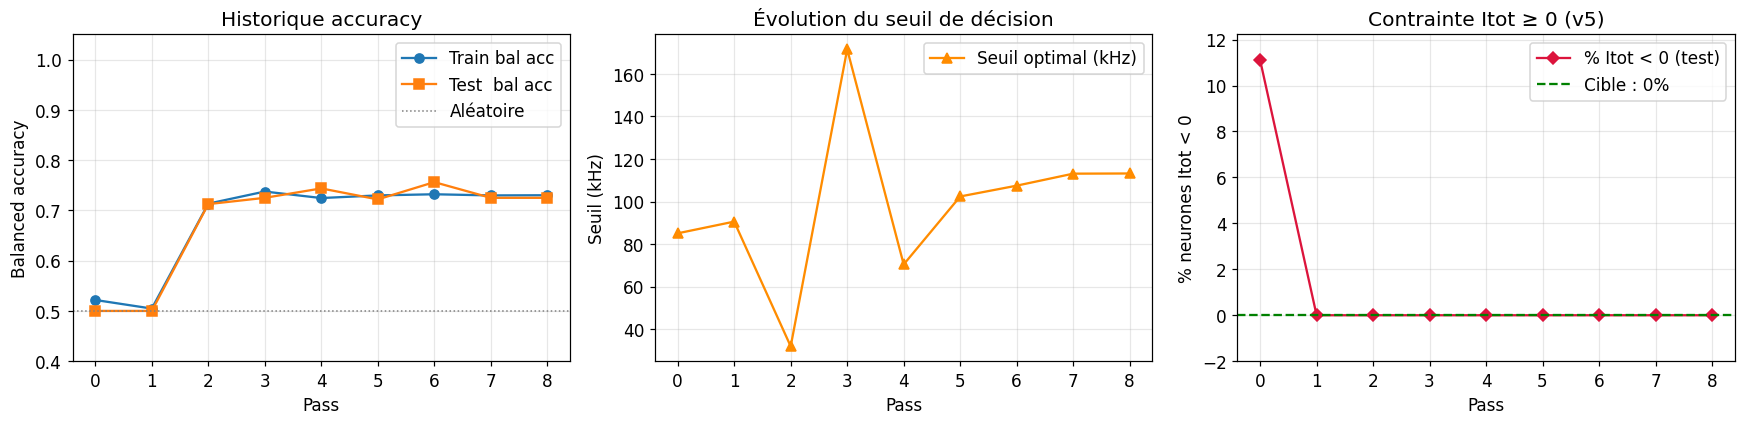

In [ ]:
# Évaluation déterministe avec le seuil fixé (trouvé sur le train)
m_train = evaluate_network(V_train, y_train, signs, widths,
                            threshold=best_threshold)
m_test  = evaluate_network(V_test,  y_test,  signs, widths,
                            threshold=best_threshold)
print_results('TRAIN (déterministe)', m_train)
print_results('TEST  (déterministe)', m_test)

# Évaluation robuste Monte-Carlo
m_train_rob = evaluate_network(V_train, y_train, signs, widths,
                                threshold=best_threshold,
                                noise_std=NOISE_STD_HZ, n_mc=N_MC_EVAL)
m_test_rob  = evaluate_network(V_test,  y_test,  signs, widths,
                                threshold=best_threshold,
                                noise_std=NOISE_STD_HZ, n_mc=N_MC_EVAL)
print_results('TRAIN (robuste MC)', m_train_rob)
print_results('TEST  (robuste MC)', m_test_rob)

if history:
    passes = [h['pass'] for h in history]
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))

    ax = axes[0]
    ax.plot(passes, [h['tr_bal_acc'] for h in history], 'o-', label='Train bal acc')
    ax.plot(passes, [h['va_bal_acc'] for h in history], 's-', label='Test  bal acc')
    ax.axhline(0.5, color='gray', ls=':', lw=1, label='Aléatoire')
    ax.set_xlabel('Pass'); ax.set_ylabel('Balanced accuracy')
    ax.set_title('Historique accuracy')
    ax.set_ylim(0.4, 1.05); ax.legend(); ax.grid(True, alpha=0.3)

    ax = axes[1]
    ax.plot(passes, [h['threshold_khz'] for h in history],
            '^-', color='darkorange', label='Seuil optimal (kHz)')
    ax.set_xlabel('Pass'); ax.set_ylabel('Seuil (kHz)')
    ax.set_title('Évolution du seuil de décision')
    ax.legend(); ax.grid(True, alpha=0.3)

    ax = axes[2]
    ax.plot(passes, [h['va_itot_neg_pct'] for h in history],
            'D-', color='crimson', label='% Itot < 0 (test)')
    ax.axhline(0, color='green', ls='--', lw=1.5, label='Cible : 0%')
    ax.set_xlabel('Pass'); ax.set_ylabel('% neurones Itot < 0')
    ax.set_title('Contrainte Itot ≥ 0 (v5)')
    ax.set_ylim(-2, max(5, max(h['va_itot_neg_pct'] for h in history) * 1.1))
    ax.legend(); ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

## 10. Distribution des fréquences de sortie + seuil

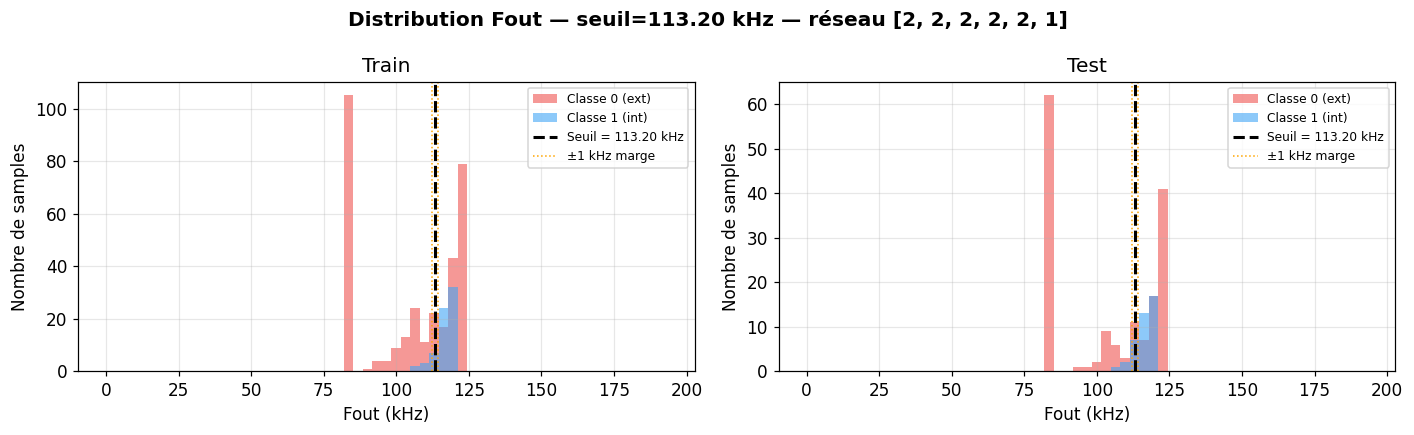

In [ ]:
# Histogramme des Fout par classe — visualise la séparation et le seuil
Fout_train = network_forward_dataset(V_train, signs, widths)
Fout_test  = network_forward_dataset(V_test,  signs, widths)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
fig.suptitle(f'Distribution Fout — seuil={best_threshold*1e-3:.2f} kHz — réseau {LAYER_SIZES}',
             fontweight='bold')

for ax, Fout, y, title in [
    (axes[0], Fout_train, y_train, 'Train'),
    (axes[1], Fout_test,  y_test,  'Test')
]:
    bins = np.linspace(0, _F_MAX, 60)
    ax.hist(Fout[y==0]*1e-3, bins=bins*1e-3, alpha=0.6,
            color='#EF5350', label='Classe 0 (ext)')
    ax.hist(Fout[y==1]*1e-3, bins=bins*1e-3, alpha=0.6,
            color='#42A5F5', label='Classe 1 (int)')
    ax.axvline(best_threshold*1e-3, color='k', lw=2, ls='--',
               label=f'Seuil = {best_threshold*1e-3:.2f} kHz')
    ax.axvline((best_threshold - MIN_MARGIN_HZ)*1e-3, color='orange',
               lw=1, ls=':', label='±1 kHz marge')
    ax.axvline((best_threshold + MIN_MARGIN_HZ)*1e-3, color='orange', lw=1, ls=':')
    ax.set_xlabel('Fout (kHz)')
    ax.set_ylabel('Nombre de samples')
    ax.set_title(title)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 11. Carte de décision

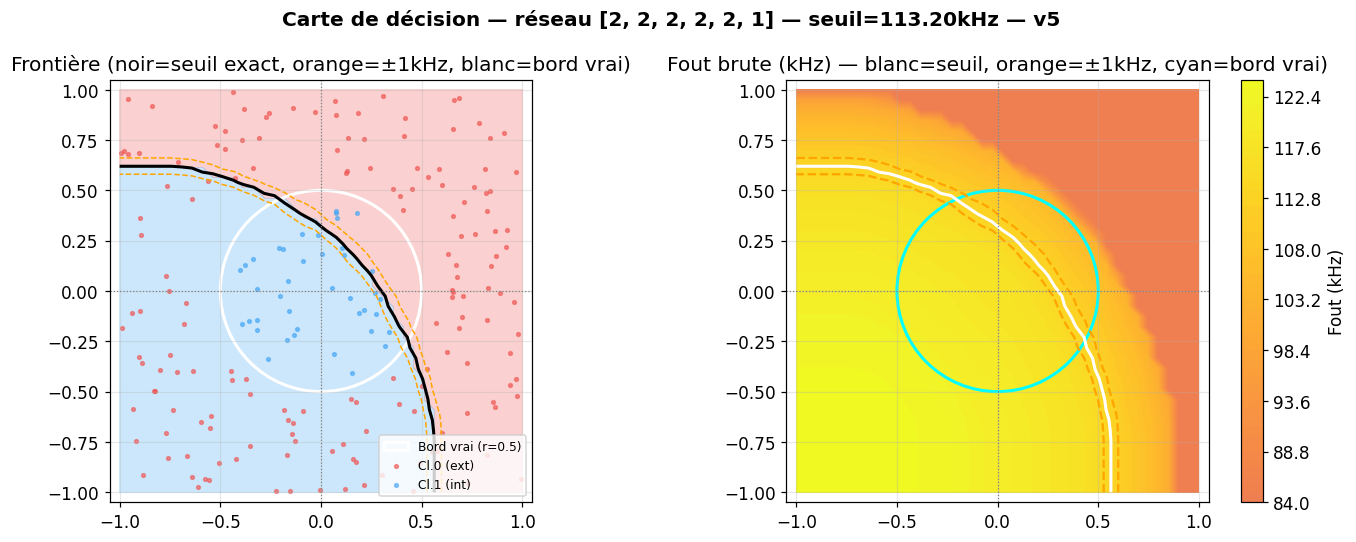

In [ ]:
resolution = 40
xs = np.linspace(-1, 1, resolution)
ys = np.linspace(-1, 1, resolution)
XX, YY = np.meshgrid(xs, ys)
grid_V = xy_to_voltage(np.column_stack([XX.ravel(), YY.ravel()]))

Fout_grid  = network_forward_dataset(grid_V, signs, widths)   # (N,) scalaire
pred_grid  = (Fout_grid >= best_threshold).astype(int).reshape(XX.shape)
# Marge signée : positive = côté correct par rapport au seuil
# On affiche Fout - seuil directement (>0 = classe 1, <0 = classe 0)
fout_grid_khz = (Fout_grid.reshape(XX.shape) - best_threshold) * 1e-3

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle(
    f'Carte de décision — réseau {LAYER_SIZES} — seuil={best_threshold*1e-3:.2f}kHz — v5',
    fontweight='bold')

ax = axes[0]
ax.contourf(XX, YY, pred_grid, levels=[-0.5, 0.5, 1.5],
            colors=['#EF535044', '#42A5F544'])
ax.contour(XX, YY, fout_grid_khz, levels=[0], colors='k', linewidths=2,
           label='Frontière (Fout=seuil)')
ax.contour(XX, YY, fout_grid_khz, levels=[-1.0], colors='orange',
           linewidths=1, linestyles='--')   # seuil - 1kHz
ax.contour(XX, YY, fout_grid_khz, levels=[+1.0], colors='orange',
           linewidths=1, linestyles='--')   # seuil + 1kHz
circle_ref = plt.Circle((0, 0), DISK_RADIUS, color='white', fill=False,
                          lw=2, ls='-', label=f'Bord vrai (r={DISK_RADIUS})')
ax.add_patch(circle_ref)
ax.scatter(X_test[y_test==0, 0], X_test[y_test==0, 1],
           s=6, c='#EF5350', alpha=0.6, label='Cl.0 (ext)')
ax.scatter(X_test[y_test==1, 0], X_test[y_test==1, 1],
           s=6, c='#42A5F5', alpha=0.6, label='Cl.1 (int)')
ax.axhline(0, color='gray', lw=0.8, ls=':')
ax.axvline(0, color='gray', lw=0.8, ls=':')
ax.set_title('Frontière (noir=seuil exact, orange=±1kHz, blanc=bord vrai)')
ax.set_aspect('equal')
ax.set_xlim(-1.05, 1.05); ax.set_ylim(-1.05, 1.05)
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

ax = axes[1]
Fout_grid_khz_abs = Fout_grid.reshape(XX.shape) * 1e-3
vmax = float(Fout_grid_khz_abs.max())
cf = ax.contourf(XX, YY, Fout_grid_khz_abs, levels=50, cmap='plasma', vmin=0, vmax=vmax)
plt.colorbar(cf, ax=ax, label='Fout (kHz)')
ax.contour(XX, YY, fout_grid_khz, levels=[0], colors='white', linewidths=2)
ax.contour(XX, YY, fout_grid_khz, levels=[-1.0, 1.0], colors='orange',
           linewidths=1.5, linestyles='--')
circle_ref2 = plt.Circle((0, 0), DISK_RADIUS, color='cyan', fill=False, lw=2, ls='-')
ax.add_patch(circle_ref2)
ax.axhline(0, color='gray', lw=0.8, ls=':')
ax.axvline(0, color='gray', lw=0.8, ls=':')
ax.set_title('Fout brute (kHz) — blanc=seuil, orange=±1kHz, cyan=bord vrai)')
ax.set_aspect('equal')
ax.set_xlim(-1.05, 1.05); ax.set_ylim(-1.05, 1.05)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 12. Diagnostic Cadence — plages de courant

In [ ]:
print('=' * 70)
print('  DIAGNOSTIC — Itot par couche vs plage neurone')
print('  Plage neurone : ['
      + str(round(NEURON_I_AXIS[0]*1e12, 1)) + ' pA, '
      + str(round(NEURON_I_AXIS[-1]*1e12, 1)) + ' pA]')
print('  Rheobase : ' + str(round(NEURON_I_RHEOBASE*1e12, 2)) + ' pA')
print('  CONTRAINTE v5 : Itot ≥ 0 pA')
print('=' * 70)

all_itot_by_layer = [[] for _ in range(len(LAYER_SIZES) - 1)]
for Vin in V_train:
    F = np.array([input_f_of_v(v) for v in Vin])
    for li, (sm, wm) in enumerate(zip(signs, widths)):
        F, _, Itot = layer_forward(F, sm, wm)
        all_itot_by_layer[li].extend(Itot.tolist())

n_lo = NEURON_I_AXIS[0]
n_hi = NEURON_I_AXIS[-1]
overall_ok = True

for li, itots in enumerate(all_itot_by_layer):
    itots = np.array(itots)
    lo, hi = itots.min(), itots.max()
    pct_neg    = 100 * np.mean(itots < 0.0)
    pct_silent = 100 * np.mean((itots >= 0.0) & (itots < n_lo))
    pct_sat    = 100 * np.mean(itots > n_hi)

    itot_str = ('✓ OK' if pct_neg == 0
                else f'✗ VIOLATION {pct_neg:.2f}% < 0 !')
    if pct_neg > 0:
        overall_ok = False

    cadence_str = (f'⚠ {pct_sat:.1f}% saturés' if pct_sat > 0
                   else f'OK ({pct_silent:.1f}% silencieux)' if pct_silent > 0
                   else 'OK — tous dans la plage')

    print(f'  Couche {li}: [{lo*1e12:.1f}, {hi*1e12:.1f}] pA')
    print(f'          Itot < 0 : {itot_str}')
    print(f'          Cadence  : {cadence_str}')

print('=' * 70)
if overall_ok:
    print('  ✓ CONTRAINTE v5 RESPECTÉE — aucun Itot < 0.')
else:
    print('  ✗ CONTRAINTE v5 VIOLÉE — Itot < 0 subsistants.')
    print('    → Augmenter MIN_ITOT_PENALTY ou N_RESTARTS.')
print('=' * 70)

  DIAGNOSTIC — Itot par couche vs plage neurone
  Plage neurone : [3.0 pA, 1000.0 pA]
  Rheobase : 3.0 pA
  CONTRAINTE v5 : Itot ≥ 0 pA
  Couche 0: [1.4, 830.5] pA
          Itot < 0 : ✓ OK
          Cadence  : OK (13.8% silencieux)
  Couche 1: [-0.1, 293.5] pA
          Itot < 0 : ✗ VIOLATION 0.38% < 0 !
          Cadence  : OK (11.0% silencieux)
  Couche 2: [0.2, 681.5] pA
          Itot < 0 : ✓ OK
          Cadence  : OK (13.1% silencieux)
  Couche 3: [2.6, 1048.1] pA
          Itot < 0 : ✓ OK
          Cadence  : ⚠ 50.0% saturés
  Couche 4: [153.7, 315.0] pA
          Itot < 0 : ✓ OK
          Cadence  : OK — tous dans la plage
  ✗ CONTRAINTE v5 VIOLÉE — Itot < 0 subsistants.
    → Augmenter MIN_ITOT_PENALTY ou N_RESTARTS.


## 13. Export des poids pour Cadence

In [ ]:
layer_names = (['In->H1']
               + ['H' + str(k) + '->H' + str(k+1) for k in range(1, len(signs) - 1)]
               + ['H' + str(len(signs) - 1) + '->Out'])

print('\n=== POIDS FINAUX réseau ' + str(LAYER_SIZES) + ' — 1 sortie — seuil='
      + str(round(best_threshold*1e-3, 3)) + ' kHz ===')
for k, (s, w, ln) in enumerate(zip(signs, widths, layer_names)):
    print(f'\n  Couche {k+1} [{ln}]  {s.shape[0]}->{s.shape[1]}')
    print('    Signes :\n' + str(s))
    print('    Largeurs (um) :\n' + str(w))
    print('    EXC=' + str(int((s == +1).sum()))
          + '  INH=' + str(int((s == -1).sum())))

rows = []
for li, (s, w) in enumerate(zip(signs, widths)):
    n_in, n_out = s.shape
    for i in range(n_in):
        for j in range(n_out):
            rows.append({
                'layer':    li + 1,
                'pre':      i,
                'post':     j,
                'sign':     int(s[i, j]),
                'width_um': float(w[i, j]),
                'type':     'EXC' if s[i, j] == 1 else 'INH'
            })

df_weights = pd.DataFrame(rows)
df_weights.to_csv('weights_cadence_disk_v5_1out.csv', index=False)

# Export du seuil séparément
df_threshold = pd.DataFrame([{
    'threshold_Hz': best_threshold,
    'threshold_kHz': best_threshold * 1e-3
}])
df_threshold.to_csv('threshold_cadence_disk_v5_1out.csv', index=False)

print('\nweights_cadence_disk_v5_1out.csv généré :')
print(df_weights.to_string(index=False))
print(f'\nthreshold_cadence_disk_v5_1out.csv : {best_threshold*1e-3:.3f} kHz')


=== POIDS FINAUX réseau [2, 2, 2, 2, 2, 1] — 1 sortie — seuil=113.199 kHz ===

  Couche 1 [In->H1]  2->2
    Signes :
[[ 1 -1]
 [ 1 -1]]
    Largeurs (um) :
[[2.246  0.8634]
 [2.095  0.9545]]
    EXC=2  INH=2

  Couche 2 [H1->H2]  2->2
    Signes :
[[ 1 -1]
 [ 1  1]]
    Largeurs (um) :
[[0.135  0.4537]
 [2.397  0.2858]]
    EXC=3  INH=1

  Couche 3 [H2->H3]  2->2
    Signes :
[[ 1 -1]
 [-1  1]]
    Largeurs (um) :
[[2.246  0.1805]
 [0.6358 0.4366]]
    EXC=2  INH=2

  Couche 4 [H3->H4]  2->2
    Signes :
[[ 1 -1]
 [ 1  1]]
    Largeurs (um) :
[[2.397  0.2261]
 [0.8889 0.5874]]
    EXC=3  INH=1

  Couche 5 [H4->Out]  2->1
    Signes :
[[-1]
 [ 1]]
    Largeurs (um) :
[[0.135]
 [2.698]]
    EXC=1  INH=1

weights_cadence_disk_v5_1out.csv généré :
 layer  pre  post  sign  width_um type
     1    0     0     1    2.2460  EXC
     1    0     1    -1    0.8634  INH
     1    1     0     1    2.0950  EXC
     1    1     1    -1    0.9545  INH
     2    0     0     1    0.1350  EXC
     2    